# Maxwell CMOS/CCD microlens — diffraction-limited focus & angular response
A sensor pixel is tiny. At a ~2 μm pitch with λ ≈ 0.5 μm, the microlens that
funnels light onto the photodiode is only ~4λ across, and the spot it forms is
~λ wide — comparable to the photosite itself. That is the regime where geometric
ray tracing quietly stops being valid: there are no "rays" at this scale, only a
diffracting field. This example solves the full time-harmonic Maxwell field for a
3-pixel cross-section and sweeps the chief-ray angle (CRA) to show the focus
walking off the photosite and spilling into the neighbour — i.e. the pixel's
*angular response* and *optical crosstalk*, both of which are pure wave effects.

Why a full-wave solver is required (and ray tracing is not enough)
------------------------------------------------------------------
A ray tracer treats the microlens as an ideal imaging element and predicts a
point focus that the chief ray drags sideways by ~f·tan(CRA). We overlay exactly
that prediction (the ✕ marker) on each field map. The real field tells a
different story:
  * the focus is a diffraction-limited *blob* ~λ wide, not a point — so even at
    normal incidence a finite fraction misses a sub-λ photosite;
  * as the CRA grows the blob walks off the photosite AND broadens/distorts
    (coma + the sub-λ metal aperture diffracts), so the collected signal rolls
    off faster than any cos⁴/vignetting cartoon and light leaks into the
    neighbouring pixel — crosstalk a ray model cannot produce.

Geometry (2D cross-section; propagation = X, pixel pitch = Y)
-------------------------------------------------------------
  * 3 pixels on a 2 μm pitch. Each microlens is a shallow spherical cap
    (n = 1.5, chord = pitch = 2 μm, radius of curvature R_c = 1.5 μm, sag
    ≈ 0.38 μm), convex side toward the incoming light, flat side down.
  * Below the lenses, an SiO₂-like spacer (n = 1.46) carries the converging
    light to the sensor plane (the curved air/lens interface does the focusing;
    lens→oxide is nearly index-matched, so almost no reflection there).
  * At the sensor plane, an opaque lossy "metal" layer (n = 1 + 3j) with a
    1 μm-wide gap per pixel = the CMOS metal stack defining each photosite.
    The collected signal is ∫|E_z|² over a thin band just behind each gap.
  * 2D via a one-pixel-thick, periodic-z domain; TM polarization (E along the
    pixel, z-polarized) — the natural 2D Maxwell mode here.

The CRA is set with an apodized, angled ``gaussian_beam`` (theta = the phase
ramp tilts the wavefront in the X-Y plane). The beam illuminates ONLY the centre
lens (FWHM ≈ one pitch), and its launch point is shifted by -tan(CRA)·x_vertex so
the tilted beam still lands centred on the centre lens at the front surface
(compensating its sideways walk over the run-up). That way the centre lens sees
the same illumination at every angle, and ANY signal in a neighbouring photosite
is unambiguously optical crosstalk -- not that neighbour focusing its own light.
The beam is apodized to ~0 before the neighbours, so there is no hard-aperture
diffraction from the source.

Four 2D runs (CRA = 0, 10, 20, 30°). Outputs, in output/mx_microlens/:
  * mx_microlens_fields.png   — 2×2 |E_z| maps with the photosite
    gaps, metal plane, and ray-predicted focus (✕) overlaid;
  * mx_microlens_response.png — collected signal per pixel vs CRA
    (centre-pixel angular roll-off + crosstalk into the neighbours).

Reuses ``wsutils.create_source.gaussian_beam`` for the angled illumination; the
pixel stack (lenses + oxide + apertured metal) is built directly with NumPy.

Size: 4 solves, the largest 0.097 Mvoxel including boundaries, 0.005 GB of memory (service estimate).

In [1]:
from time import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

from wsutils import output_dir
from wsutils.create_source import gaussian_beam
from wavesimpro import configure, simulate

NAME = "mx_microlens"   # run name on the service and output folder
OUTPUT_DIR = output_dir(NAME)   # <repo root>/output/<NAME>
configure(description=NAME, folder=NAME)  # every solve goes in one folder

### Parameters

In [2]:
wavelength = 0.5  # Wavelength in micrometer (μm) — green light
pixel_size = 0.04  # Grid pixel in μm (~12.5 px/λ in air, ~8 px/λ in the lens; fine
#                    for a curved cap. Drop to 0.03 for a finer grid, ~1.8x the voxels.)

# Domain: X = propagation/depth into the stack, Y = pixel-pitch direction.
sim_size = np.array([7.0, 8.0])  # (x, y) simulation size in micrometer (μm)
n_size = (sim_size / pixel_size).astype(int)
nx, ny = int(n_size[0]), int(n_size[1])

# Pixel array: 3 pixels on a 2 μm pitch, centred in Y.
pitch = 2.0  # Pixel pitch in μm
pixel_centers = np.array([2.0, 4.0, 6.0])  # Y of each photosite centre, μm
center_pixel = 1  # index of the centre pixel (the one we report angular response for)

# Microlens: shallow spherical cap, convex side up (toward the incoming light).
lens_index = 1.5  # Microlens refractive index
oxide_index = 1.46  # SiO₂-like spacer below the lenses
bg_index = 1.0  # Air above the lenses
R_c = 1.5  # Radius of curvature of the cap, μm
chord = pitch  # Lens diameter = pitch (≈100% fill microlens array), μm
half_chord = chord / 2
# Cap geometry: vertex (closest point to the light) at x_vertex; the defining
# sphere's centre sits a distance R_c downstream of the vertex; the flat base is
# where the sphere's cross-section first reaches the full chord.
x_vertex = 2.0  # X of the curved vertex, μm (leaves ~1 μm clear air after the boundary)
x_sphere = x_vertex + R_c  # X of the defining sphere centre, μm
x_base = x_sphere - np.sqrt(R_c**2 - half_chord**2)  # X of the flat base, μm
sag = x_base - x_vertex  # cap height, μm
focal_from_vertex = R_c / (lens_index - bg_index)  # paraxial f from the vertex, μm
x_focus = x_vertex + focal_from_vertex  # paraxial focus depth, μm (orientation only)

# Sensor plane: opaque metal layer with a photosite gap per pixel.
x_metal = x_focus  # put the metal/photosite plane at the paraxial focus, μm
t_metal = 0.3  # metal thickness, μm (a few absorption lengths → opaque)
metal_index = 1.0 + 3.0j  # generic lossy/opaque mask (absorbs AND reflects)
photosite_width = 1.0  # gap width per pixel ≈ 50% fill factor, μm

# Collection band: a thin slab just behind the metal where we integrate |E_z|².
x_collect0 = x_metal + t_metal + 0.05  # start, μm
x_collect1 = x_collect0 + 0.4  # end, μm

# Chief-ray angles to sweep.
angles_deg = [0, 10, 20, 30]

print(f"Microlens: n={lens_index}, chord={chord} μm, R_c={R_c} μm, sag={sag:.3f} μm")
print(f"Cap: vertex X={x_vertex} μm, flat base X={x_base:.3f} μm; paraxial f≈{focal_from_vertex:.2f} μm "
      f"(focus X≈{x_focus:.2f} μm, NA≈{half_chord/focal_from_vertex:.2f})")
print(f"Diffraction-limited spot ≈ λ/(2·NA) ≈ {wavelength/(2*half_chord/focal_from_vertex):.2f} μm "
      f"vs photosite {photosite_width} μm")
print(f"Sensor/metal plane X={x_metal:.2f} μm, gaps {photosite_width} μm at Y={pixel_centers}")

Microlens: n=1.5, chord=2.0 μm, R_c=1.5 μm, sag=0.382 μm
Cap: vertex X=2.0 μm, flat base X=2.382 μm; paraxial f≈3.00 μm (focus X≈5.00 μm, NA≈0.33)
Diffraction-limited spot ≈ λ/(2·NA) ≈ 0.75 μm vs photosite 1.0 μm
Sensor/metal plane X=5.00 μm, gaps 1.0 μm at Y=[2. 4. 6.]


### Medium: microlenses + oxide spacer + apertured metal

In [3]:
def build_pixel_stack():
    """Returns permittivity (n²) as a (nx, ny, 1) array (one pixel thick in z)."""
    x = np.arange(nx) * pixel_size
    y = np.arange(ny) * pixel_size
    X, Y = np.meshgrid(x, y, indexing="ij")  # (nx, ny)

    n = np.full((nx, ny), bg_index, dtype=np.complex64)  # background air

    # Oxide spacer: everything from the lens base down to the metal plane.
    n[(X >= x_base) & (X < x_metal)] = oxide_index

    # Microlens caps: inside the defining sphere AND upstream of the flat base.
    for yc in pixel_centers:
        inside_sphere = (X - x_sphere) ** 2 + (Y - yc) ** 2 < R_c**2
        n[inside_sphere & (X <= x_base)] = lens_index

    # Opaque metal layer with a photosite gap per pixel.
    in_metal = (X >= x_metal) & (X < x_metal + t_metal)
    n[in_metal] = metal_index
    for yc in pixel_centers:
        gap = in_metal & (np.abs(Y - yc) <= photosite_width / 2)
        n[gap] = oxide_index  # open the photosite (filled with oxide, not metal)

    return (n**2).astype(np.complex64)[..., None]


permittivity = build_pixel_stack()

### Sweep the chief-ray angle

In [4]:
def collected_signal(ez):
    """∫|E_z|² over the collection band, per photosite. Returns one value/pixel."""
    x = np.arange(ez.shape[0]) * pixel_size
    y = np.arange(ez.shape[1]) * pixel_size
    band = (x >= x_collect0) & (x <= x_collect1)
    intensity = np.abs(ez[band, :]) ** 2  # (n_band, ny)
    signals = []
    for yc in pixel_centers:
        win = np.abs(y - yc) <= photosite_width / 2
        signals.append(float(intensity[:, win].sum()))
    return np.array(signals)


fields = []  # E_z (nx, ny) per angle
signals = []  # collected signal per pixel per angle

for theta_deg in angles_deg:
    theta = np.deg2rad(theta_deg)
    # Illuminate ONLY the centre lens: a ~one-pitch-FWHM apodized beam, and shift
    # the launch point by -tan(theta)*x_vertex so the tilted beam still lands
    # centred on the centre lens at its front surface (it walks tan(theta)*x_vertex
    # over the run-up). The centre lens then sees identical illumination at every
    # angle, so ANY signal in a neighbouring photosite is pure optical crosstalk,
    # not that neighbour focusing its own light. The phase ramp (theta) tilts the
    # wavefront in the X-Y plane = the chief-ray angle. Launched at X=0 (upstream
    # boundary) so the absorber swallows the backward-radiated half.
    y_src = pixel_centers[center_pixel] - np.tan(theta) * x_vertex
    source_values, source_position = gaussian_beam(
        shape=4.0,  # ~2-pitch window, apodized to ~0 before the neighbours, μm
        origin="center",
        position=[2, 0.0, y_src, 0.0],  # z-polarized (TM), centred on the centre lens, at X=0
        source_plane="y",
        pixel_size=pixel_size,
        theta=theta,  # incidence angle (CRA), radians
        wavelength=wavelength,
        waist=1.167,  # field FWHM ≈ one lens: fills the centre lens, misses the neighbours
    )

    print(f"\nCRA = {theta_deg:>2}° — running simulation...")
    start = time()
    u, iterations, residual_norm = simulate(
        permittivity=permittivity,
        sources=[(source_values, source_position)],
        wavelength=wavelength,
        pixel_size=pixel_size,
        boundary_width=2.5,  # absorbing boundary width, μm (≈5 λ)
        periodic=(False, False, True),  # periodic in z -> 2D (infinite in z)
    )
    print(f"  Time {time() - start:.1f} s; Iterations {iterations}")

    ez = u[2]
    if ez.ndim == 3:
        ez = ez[:, :, ez.shape[2] // 2]
    fields.append(ez)

    s = collected_signal(ez)
    signals.append(s)
    print(f"  Collected per pixel (y=2, 4, 6 μm): "
          f"{np.array2string(s / s.max(), precision=3)}")

signals = np.array(signals)  # (n_angles, 3)


CRA =  0° — running simulation...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : bc79e179-d919-4058-b535-96fab7032eb6
  Version   : 90040820-0ed8-4bad-bf5c-a77bbc86ea14
  Command   : 0562141c-9d61-4637-b8d9-f4fb01a2b085
  Mode      : Maxwell (vectorial)
  Domain    : 175x200x1 voxels  lambda=0.5 um  dx=0.040 um
  Engine    : Any (auto-select)  |  GPU: auto
  Threshold : 1.0e-06  max iter: 100000
  ------------------------------------------------------
  Time 29.6 s; Iterations 1518
  Collected per pixel (y=2, 4, 6 μm): [0.038 1.    0.033]

CRA = 10° — running simulation...

  ------------------------------------------------------
  Rayfos remote simulation
  ------------------------------------------------------
  Project   : a9111267-9e4c-4dad-ace2-23a4c958b443
  Version   : a0d8baff-55d1-4b0c-9b26-8086c152a9e5
  Command   : 7596753a-cec2-4966-9b04-5a841cc9f9a4
  Mode      : M

### Figure 1: field maps with photosite / metal / ray-focus overlays

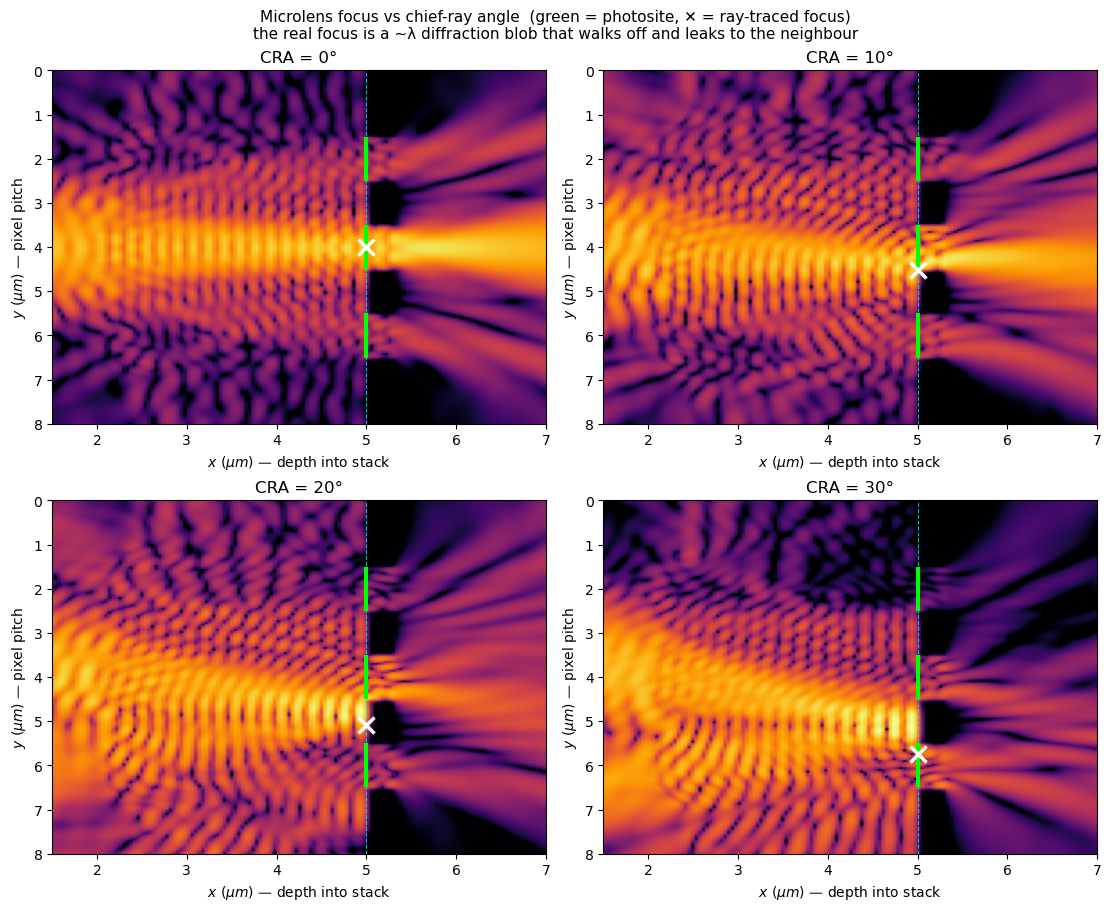

In [5]:
# Shared log color scale across angles so they are directly comparable. Two
# decades (not three) suppresses the low-level metal-reflection standing-wave
# ripple upstream and pops the focusing cone.
vmax = max(np.abs(f).max() for f in fields)
vmin = vmax * 1e-2
extent = [0, nx * pixel_size, ny * pixel_size, 0]  # x horizontal, y vertical (origin top)

fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
for ax, theta_deg, ez in zip(axes.flat, angles_deg, fields):
    ax.imshow(np.abs(ez).T, cmap="inferno", extent=extent,
              norm=colors.LogNorm(vmin=vmin, vmax=vmax), aspect="auto")
    # Metal plane (sensor) and its photosite gaps.
    ax.axvline(x_metal, color="cyan", lw=0.8, ls="--", alpha=0.7)
    for yc in pixel_centers:
        ax.plot([x_metal, x_metal], [yc - photosite_width / 2, yc + photosite_width / 2],
                color="lime", lw=3, solid_capstyle="butt")
    # Ray-traced (paraxial) focus the chief ray would predict: walks by f·tan(CRA).
    y_ray = pixel_centers[center_pixel] + focal_from_vertex * np.tan(np.deg2rad(theta_deg))
    ax.plot(x_focus, y_ray, "x", color="white", ms=11, mew=2.5)
    ax.set_xlim(1.5, nx * pixel_size)  # crop off the source run-up and its clutter
    ax.set_title(f"CRA = {theta_deg}°")
    ax.set_xlabel(r"$x~(\mu m)$ — depth into stack")
    ax.set_ylabel(r"$y~(\mu m)$ — pixel pitch")
fig.suptitle("Microlens focus vs chief-ray angle  "
             "(green = photosite, ✕ = ray-traced focus)\n"
             "the real focus is a ~λ diffraction blob that walks off and leaks to the neighbour",
             fontsize=11)
fig.savefig(f"{OUTPUT_DIR}/mx_microlens_fields.png", dpi=300, bbox_inches="tight")

### Figure 2: angular response & crosstalk


Angular response (centre pixel, norm. to 0°): [1.    0.7   0.182 0.037]
Crosstalk into neighbours (sum, norm. to centre @ 0°): [0.072 0.065 0.035 0.062]
Saved output/mx_microlens/mx_microlens_fields.png and output/mx_microlens/mx_microlens_response.png


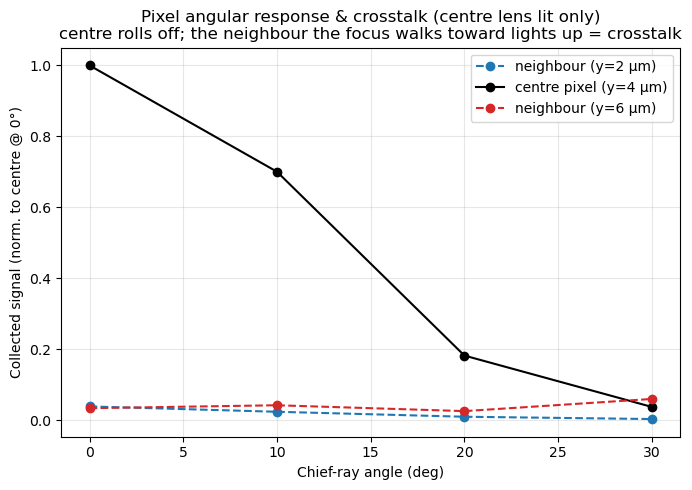

In [6]:
norm = signals[0, center_pixel]  # normalize to the centre pixel at normal incidence
fig2, ax2 = plt.subplots(figsize=(7, 5))
labels = ["neighbour (y=2 μm)", "centre pixel (y=4 μm)", "neighbour (y=6 μm)"]
styles = [("tab:blue", "--o"), ("k", "-o"), ("tab:red", "--o")]
for k, (lab, (c, st)) in enumerate(zip(labels, styles)):
    ax2.plot(angles_deg, signals[:, k] / norm, st, color=c, label=lab)
ax2.set_xlabel("Chief-ray angle (deg)")
ax2.set_ylabel("Collected signal (norm. to centre @ 0°)")
ax2.set_title("Pixel angular response & crosstalk (centre lens lit only)\n"
              "centre rolls off; the neighbour the focus walks toward lights up = crosstalk")
ax2.grid(True, alpha=0.3)
ax2.legend()
fig2.tight_layout()
fig2.savefig(f"{OUTPUT_DIR}/mx_microlens_response.png", dpi=300, bbox_inches="tight")

print("\nAngular response (centre pixel, norm. to 0°):",
      np.array2string(signals[:, center_pixel] / norm, precision=3))
print("Crosstalk into neighbours (sum, norm. to centre @ 0°):",
      np.array2string((signals[:, 0] + signals[:, 2]) / norm, precision=3))
print(f"Saved output/{NAME}/mx_microlens_fields.png and output/{NAME}/mx_microlens_response.png")

plt.show()